<!--start-block-->
<h3 style="text-align: center; font-size: 24pt;"> Dark Matter Halos Detection using Constrained Multivariate Gaussian Mixture Models</h3>
<div style="text-align: right;">
    <img src="res/UniWien.jpg" alt="Description" width="200">
</div>
<h3 style="text-align: right; font-size: 14pt;"> Final Assignment: Statistical Methods of Data Analysis (2024W)</h3>
<h3 style="text-align: right; font-size: 14pt;"> Present by: Iman Zabett (a01325278) - University of Vienna</h3>
<h3 style="text-align: right; font-size: 14pt;"> Instructor: Prof. Waltenberger </h3>


<a name='section_1_0'></a>
<hr style="height: 1px;">
<h3>CONTENTS</h3>
          
<table style="width:100%">
    <tr>
        <td style="text-align: left; vertical-align: top; font-size: 14pt;"><a href="#section_1">P1. Poblem Statement¶</a></td>
        <td style="text-align: left; vertical-align: top; font-size: 10pt;">P1.1. Dark Matter Halos Detection<br>P1.2. AstroPhysics Challenges<br>P1.3. Data Science Challenges</td>
    </tr>
    <tr>
        <td style="text-align: left; vertical-align: top; font-size: 14pt;"><a href="#section_2">P2. Exploratory Data Analysis</a></td>
        <td style="text-align: left; vertical-align: top; font-size: 10pt;">P2.1. Loading data and visualization <br>P2.2. Finding optimal number of cluster `K` <br>P2.3. Exploration with typical clustering methods </td>
    </tr>
    <tr>
        <td style="text-align: left; vertical-align: top; font-size: 14pt;"><a href="#section_3">P3. Mixture Model using Maximum Likelihood Estimation</a></td>
        <td style="text-align: left; vertical-align: top; font-size: 10pt;">P3.1 Estimating the initial guess <br> P3.2. Modeling Constraints using MLE <br> P3.3. Optimization <br> P3.4. Prediction using Posterior </td>
    </tr>
    <tr>
        <td style="text-align: left; vertical-align: top; font-size: 14pt;"><a href="#section_4">P4. Conclusions</a></td>
        <td style="text-align: left; vertical-align: top; font-size: 10pt;">P4.1 Discussion <br> P4.2. Future Directions <br> P4.3. Resources <br> P3.4. Prediction using Posterior </td>
    </tr>
</table>

<!--end-block-->

<!--start-block-->
<a name='section_1'></a>
<hr style="height: 1px;">


## <h2 style="border:1px; border-style:solid; padding: 0.25em; color: #FFFFFF; background-color: #30609C">P1. Poblem Statement</h2>

<h4>P1.1. Dark Matter Halos Detection using Constrained Multivariate Gaussian Mixture Models</h4>

Halos are massive structures that surround galaxies, and they're made up of dark matter. They don't emit light, so their presence is inferred through gravitational effects on visible matter. Detecting and characterizing these halos is crucial for understanding the structure and evolution of the universe.

<div style="text-align: center;">
    <img src="res/DM Halos.jpg" alt="Description" width="800">
</div>

<div style="margin-left: 150px; margin-right: 180px;">
Left: The mid-infrared view of NGC 6357 seen by the $Spitzer\textit{ Space Telescope.}$ The molecular clouds, forming several bubbles, are seen prominently in these images but the star clusters are not immediately evident. 
    
Right: The cluster members identified from the X-ray/infrared MYStIX study, which are colorcoded by group from the mixture model. Light grey stars have ambiguous cluster memberships, and dark green stars are members of a distributed population in the model. The core-regions of the various mixture components are shown as black ellipses. "Kuhn et al. (2017). Mixture models in astronomy".
</div>


___
<h4>P1.2. AstroPhysics Challenges</h4>

+ **large-scale galaxy distribution**

    - <u>Neyman et al. , 1953  (Possion Distribution)</u>: First statistical model was proposed which is built based on three main components. Distribution of galaxies within each cluster, the size distribution of the clusters, and a description of the clustering of clusters. This model assumed overdense clusters distributed in space as Poisson process.
    - <u>de Vaucouleurs, 1971 (log-normal Distribution)</u>: Soon after Neyman et al. model, another model was proposed. This model suggests the frequency distribution of galaxy counts in quadrats followed a lognormal distribution rather than the Poisson distribution expected from spatial randomness.

+ **DM distributions:**

    - DM halos are not uniformly distributed. Existing clustering algorithms are not sufficient to model distribution of particles in simulations or observational data. These standard approaches leading to poor detection or inaccurate characterization of halo properties like mass, density profiles, or velocity dispersion.

+ **Assigning probability and classifying each particle w.r.t. its local halos/sub-halos**
___
<h4>P1.3. Data Science Challenges</h4>


+ **Data complexities and noise:**

    - Observational data (e.g. gravitational lensing, velocity measurements) typically are noisy, sparse, with overlapping signals (like overlapping halos). They offere lack of good signal-to-noise ratios. Hence, designing a robust model is a challenge.

+ **Unsupervised algorithms detecting dense regimes of space**

+ **Big data:** 

    - methods such as mixture models can improve scalability and efficiency to tackle with vast amount of Cosmoligical data.


___
## Overview
<div style="text-align: center;">
    <img src="res/pipeline.png" alt="Description" width="1000">
</div>

In [1]:
import sys
import os
from pathlib import Path
import sys
from o1_dark_full_trans import *
from importlib import reload


# Importing necessary libraries
import numpy as np
import pandas as pd
import math
from numpy.random import default_rng


%matplotlib widget
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.gridspec as gridspec

# Machine Learning Libs
from sklearn import cluster
from sklearn.mixture import BayesianGaussianMixture
from scipy.optimize import minimize
from scipy.stats import gaussian_kde
from scipy.ndimage import maximum_filter
from scipy.ndimage import gaussian_filter

# Warning Supression
import warnings
warnings.filterwarnings("ignore")

# Add Project classes and functions
%run Project_Utility.ipynb

<a name='section_2'></a>
<hr style="height: 1px;">


## <h2 style="border:1px; border-style:solid; padding: 0.25em; color: #FFFFFF; background-color: #30609C">P2. Exploratory Data Analysis</h2>


### P2.1. Loading data and visualization:

### P2.2. Finding optimal number of cluster `K`:
  - Using WCSS method and visualization, we can visually find elbows and define a proper `K for further steps.

### P2.3. Exploration with typical clustering methods:
  - The used methods include hierarchical, center-based, or density-based clustering algorithms
  - Using prediction to label data points and finding membership for each points using optimal `K`


___

___
## P2.1. Dataset and visualization:

* #### The Bolshoi Simulation:


The Bolshoi simulation was conducted to provide a detailed and statistically robust picture
of the evolution of dark matter halos—from large clusters down to subhalos—across
cosmic time.

* #### Resolution and Volume:

The simulation typically covers a cosmological volume (for example, a box of roughly 250 $h^{-1}Mpc$ on a side) using billions of dark matter particles. This combination of high spatial and mass resolution allows researchers to resolve halos and subhalos with high fidelity. $h^{-1}Mpc$ commonly used in cosmology to express distances in a way that accounts for the uncertainty in the Hubble constant $H_0$ 

In [ ]:
# Step 1: Setup
# Load the data


# Read data from file 
data = pd.read_csv("datacat.txt", sep=r"\s+", header=None)
x, y, z = data.iloc[:,1], data.iloc[:,2], data.iloc[:,3]
print(data[:5])


# Visualization of initial guess (using matplotlib for plotting)
fig = plt.figure(figsize=(8, 6))
plt.style.use('default')
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(x, y, z, c='blue', marker='o', alpha=0.2)
ax.set_xlabel('X ($h^{-1}Mpc$)')
ax.set_ylabel('Y ($h^{-1}Mpc$)')
ax.set_zlabel('Z ($h^{-1}Mpc$)')
ax.set_title(f'3D Point Distribution of Bolshoi Simulation for {len(x)} number of points')
plt.show()

## P2.2. Finding optimal number of cluster `K`:

WCSS measures the variance within each cluster. It calculates the sum of squared Euclidean
distances between each point and the centroid of its assigned cluster.
Mathematically, WCSS is defined as

$$WCSS=\sum\limits_{k=1}^K\sum\limits_{i=1}^{n_k}\|x_i-C_k\|^2$$

Where:

* $K=$Total number of clusters.
* $x_{i}=$Data points in cluster $k.$
* $C_{k}=$Centroid of cluster $k.$
* $n_{k}=$Number of points in cluster $k$

* $\| x_{i}- C_{k}\| ^{2}=$Squared Euclidean distance of each point from the centroid

2 How is WCSS Used in the Elbow Method?

The Elbow Method helps find the optimal number of clusters (K) by plotting WCSS against different

values of K

1. Run K-Means for different values of K (e.g., $K=1,2,3,\ldots,10).$

2. Compute WCSS for each K

3. Plot WCSS vs. K$\to$The graph typically shows a sharp decrease at first and then starts to level off.

4. Find the "Elbow Point" → The optimal `K` is at the "elbow," where WCSS stops decreasing significantly.

Optimal number of clusters: 3


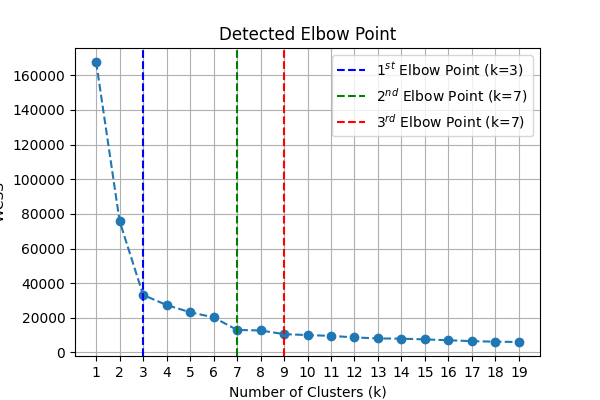

In [3]:
from kneed import KneeLocator


X3d = np.array([x,y,z]).T

# Range of clusters to evaluate
k_values = range(1, 20)

# Calculate WCSS (Within-Cluster Sum of Squares) for each k
wcss = []
for k in k_values:
    kmeans = cluster.KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X3d)
    wcss.append(kmeans.inertia_)  # WCSS for the given k


# Find the automated elbow point
knee = KneeLocator(k_values, wcss, curve="convex", direction="decreasing")

print(f"Optimal number of clusters: {knee.knee}")

# Plot with the elbow point highlighted
plt.figure(figsize=(6, 4))
plt.plot(k_values, wcss, marker='o', linestyle='--')
plt.title("Detected Elbow Point")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("WCSS")
plt.xticks(k_values)
plt.axvline(x=knee.knee, color='blue', linestyle='--', label="$1^{st}$ "+f"Elbow Point (k={knee.knee})")
plt.axvline(x=7, color='green', linestyle='--', label="$2^{nd}$ "+f"Elbow Point (k={7})")
plt.axvline(x=9, color='red', linestyle='--', label="$3^{rd}$ "+f"Elbow Point (k={7})")
plt.legend()
plt.grid()
plt.show()


## P2.3. Exploration with typical clustering methods

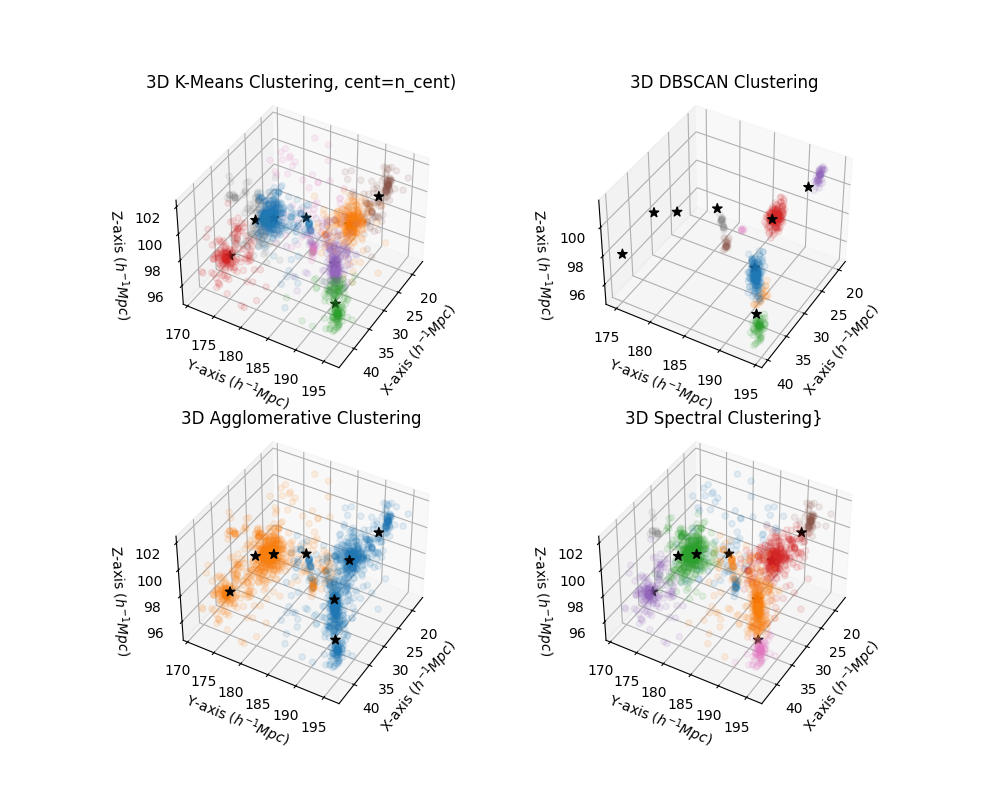

In [4]:
# Visualize the clusters for the optimal k (e.g., k=9)
from sklearn import cluster

kmeans = cluster.KMeans(random_state=42)
kmeans.fit(X3d)
labels = kmeans.labels_
centroids = kmeans.cluster_centers_
n_cent = len(centroids)

# 3D Scatter Plot of Clusters
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(221, projection='3d')
# Scatter points with cluster colors
for i in range(n_cent):
    cluster_points = X3d[labels == i]
    ax.scatter(cluster_points[:, 0], cluster_points[:, 1], cluster_points[:, 2], label=f"Cluster {i+1}", alpha=0.1)
# Cluster Centers
ax.scatter(centroids[:, 0], centroids[:, 1], centroids[:, 2],
           s=50, c='black', marker='*', label='Centroids', alpha=1)
ax.set_title("3D K-Means Clustering, cent=n_cent)")
ax.set_xlabel("X-axis ($h^{-1}Mpc$)")
ax.set_ylabel("Y-axis ($h^{-1}Mpc$)")
ax.set_zlabel("Z-axis ($h^{-1}Mpc$)")
ax.view_init(elev=40., azim=30)


dbscan = cluster.DBSCAN()
dbscan.fit(X3d)
labels = dbscan.labels_
# centroids = dbscan.cluster_centers_

ax2 = fig.add_subplot(222, projection='3d')
# Scatter points with cluster colors
for i in range(n_cent):
    cluster_points = X3d[labels == i]
    ax2.scatter(cluster_points[:, 0], cluster_points[:, 1], cluster_points[:, 2], label=f"Cluster {i+1}", alpha=0.1)
# Cluster Centers
ax2.scatter(centroids[:, 0], centroids[:, 1], centroids[:, 2],
           s=50, c='black', marker='*', label='Centroids', alpha=1)
ax2.set_title("3D DBSCAN Clustering")
ax2.set_xlabel("X-axis ($h^{-1}Mpc$)")
ax2.set_ylabel("Y-axis ($h^{-1}Mpc$)")
ax2.set_zlabel("Z-axis ($h^{-1}Mpc$)")
ax2.view_init(elev=40., azim=30)


agglo = cluster.AgglomerativeClustering()
agglo.fit(X3d)
labels = agglo.labels_
# centroids = agglo.cluster_centers_

ax3 = fig.add_subplot(223, projection='3d')
# Scatter points with cluster colors
for i in range(n_cent):
    cluster_points = X3d[labels == i]
    ax3.scatter(cluster_points[:, 0], cluster_points[:, 1], cluster_points[:, 2], label=f"Cluster {i+1}", alpha=0.1)
# Cluster Centers
ax3.scatter(centroids[:, 0], centroids[:, 1], centroids[:, 2],
           s=50, c='black', marker='*', label='Centroids', alpha=1)
ax3.set_title("3D Agglomerative Clustering")
ax3.set_xlabel("X-axis ($h^{-1}Mpc$)")
ax3.set_ylabel("Y-axis ($h^{-1}Mpc$)")
ax3.set_zlabel("Z-axis ($h^{-1}Mpc$)")
ax3.view_init(elev=40., azim=30)


spect = cluster.SpectralClustering(
        eigen_solver="arpack",
        affinity="nearest_neighbors",
        random_state=42)
spect.fit(X3d)
labels = spect.labels_
# centroids = spect.cluster_centers_

ax4 = fig.add_subplot(224, projection='3d')
# Scatter points with cluster colors
for i in range(n_cent):
    cluster_points = X3d[labels == i]
    ax4.scatter(cluster_points[:, 0], cluster_points[:, 1], cluster_points[:, 2], label=f"Cluster {i+1}", alpha=0.1)
# Cluster Centers
ax4.scatter(centroids[:, 0], centroids[:, 1], centroids[:, 2],
           s=50, c='black', marker='*', label='Centroids', alpha=1)
ax4.set_title("3D Spectral Clustering}")
ax4.set_xlabel("X-axis ($h^{-1}Mpc$)")
ax4.set_ylabel("Y-axis ($h^{-1}Mpc$)")
ax4.set_zlabel("Z-axis ($h^{-1}Mpc$)")
ax4.view_init(elev=40., azim=30)
 # plt.legend()
plt.show()


<a name='section_3'></a>
<hr style="height: 1px;">


## <h2 style="border:1px; border-style:solid; padding: 0.25em; color: #FFFFFF; background-color: #30609C">P3. Mixture Model using Maximum Likelihood Estimation</h2>


### P3.1. Estimating the initial guess:
In order to start the algorithm to run, it requires to set up an initial guess for the parameters (centers and Einasto profile).
    The initial guess vastly helps the MLE algorithm to find local maxima and converging through its itereations.
    Multiple choices have been considered to define the initial parameters from: 
    
  - random values
  - random selection of the points
  - drawing from statistical distributions as priori such as Drichlet process
  - kernel density estimation

### P3.2. Modeling Constraints using Maximum likelihood estimation (MLE):
  - defining gaussian for galaxies distribution
  - using Einasto profile as constraint
  - derivinng constrained Likelihood function 
  - forming negative log likelihood (NLL)

### P3.3. Optimization:
  - Constructing an optimization testbed and defining optimization parameters
  - Applying different optimization methods
  - picking the best performed numerical results by calculating NLL

### P3.4. Prediction using Posterior:
  - calculating posterior of Likelihood function for each data point
  - calculating probability of each point based on posterior using `softmax`
  - classifying and labeling each point

### P3.5 Performance Analysis
  - AIC/BIC metrics
  - Residual analysis: Raw, Pearson and Smoothed
___

___
## P3.1. Estimating the initial guess:

#### 1. Kernel Density Estimation (KDE) in 3D

Given a set of 3D data points $\{\mathbf{x}_1,\mathbf{x}_2,\ldots,\mathbf{x}_n\}$ where each $\mathbf{x}_i\in\mathbb{R}^3$,the kernel density estimate
(KDE) at a location $\mathbf{x}=(x,y,z)$ is typically written as


$$\hat{f}(\mathbf{x})\:=\:\frac{1}{n\:h^3}\sum_{i=1}^{n}K\biggl(\frac{\mathbf{x}-\mathbf{x}_{i}}{h}\biggr),$$

where: $n$ is the total number of data points, $h>0$ is the bandwidth, $K(\cdot)$ is the kernel function, which must integrate (in 3D) to 1 if used in a standard KDE. 

A common choice is the isotropic 3D Gaussian kernel: 
$$K(\mathbf{u})\:=\:\frac{1}{(2\pi)^{3/2}}\exp\biggl(-\frac{1}{2}\|\mathbf{u}\|^{2}\biggr),$$

where $||\mathbf{u}||$ is the Euclidean distance in $\mathbb{R}^3.$


#### 2. The `kde3d` Algorithmic Steps

High-level steps used by functions like `kde3d` often are:

1. Define a 3D grid:
For each dimension (x,y,z), pick a sequence of grid points covering the range of your data.
Typically, you get a 3D mesh of $(N_{x}\times N_{y}\times N_{z})$ locations

2. Evaluate the KDE at each grid point:

    + Compute $\hat{f}(\mathbf{x}_{\mathrm{grid}})$ using above formula.

4. Store the resulting density values in a 3D array of dimension $(N_{x},N_{y},N_{z}).$


#### 3. Finding Local Maxima and Proposing `centers` of `clusters`

Once the 3D KDE array $\hat{f}(x,y,z)$ is computed on a grid:

1. Local Maxima finding:

    + Scan each interior grid cell and compare $\hat{f}(x,y,z)$ to its 26 neighbors in 3D
    + A point$(x,y,z)$ is alocal maximum if $\hat{f}$ is larger than all neighboring values.

2. Sort by Density:

    + Collect these local maxima in a list
    + Sort them descendinq by their KDE value, so the hiqhest density peaks come first

3. Use Top `K`(number of `clusters`) Peaks as `Centers`.




##### Advantages

+ Intuition: The KDE peaks highlight regions of highest data concentration, making them natural
starting points for clusters.
+ Better Convergence: In high-dimensional or complex data, random guesses can lead to slow or
poor local minima. Or even divergence of optimization.

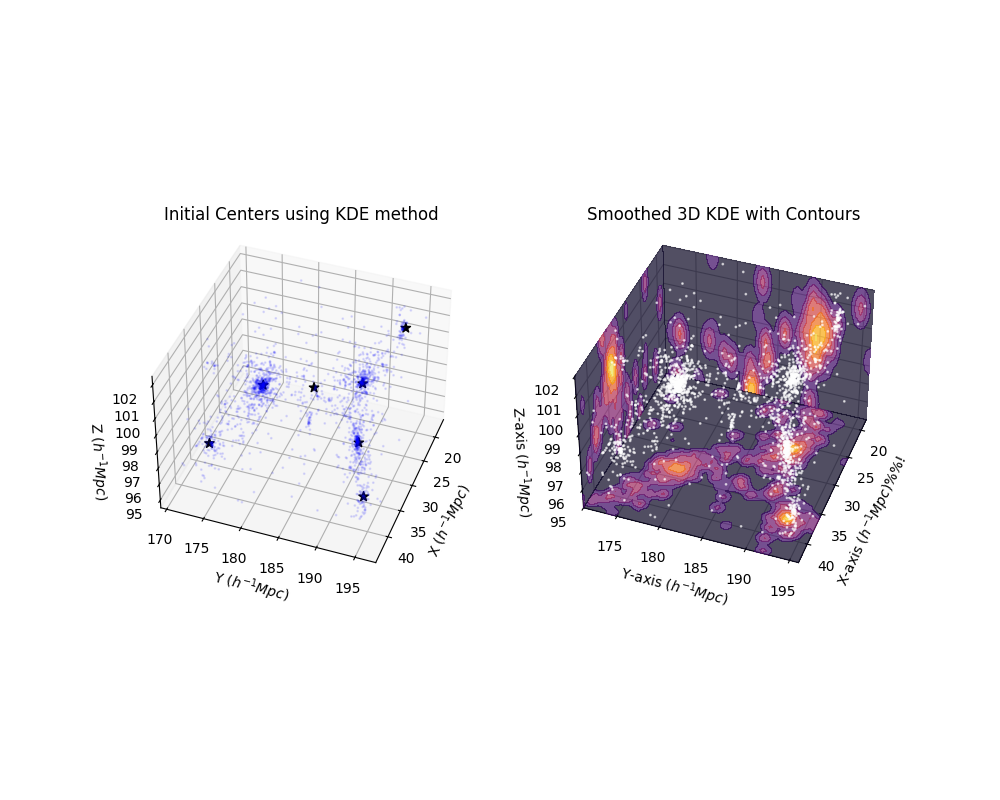

In [6]:
data = pd.read_csv('datacat.txt', delim_whitespace=True, header=None)
data = data.sample(frac=1)

# Define the ranges for x, y, z
minx, maxx = 18, 43
miny, maxy = 171, 196
minz, maxz = 95, 102

k = 7
v = 5

# Create a 3D point process object (using numpy arrays for simplicity)
x, y, z = data[1], data[2], data[3]


#  Create a PP3 object

clust = Point3DProcess(
    x=x, y=y, z=z,
    xrange=(minx, maxx),
    yrange=(miny, maxy),
    zrange=(minz, maxz)
)

ntile = (20, 20, 14)
quad = quad_3d(clust, ntile=ntile)

# Step 2: Initial guess
# Initialize parameters and generate initial guess for cluster centers
param2 = []
param2.append(k + 1)  # first item: total number of components

# For each of k Einasto halos, append (function, v) pair
for _ in range(k):
    param2.append(einasto_model)
    param2.append(v)

# Finally, add the constant background model
param2.append(const_model)
param2.append(0)


# Placeholder for param and cent (to be implemented based on specific models)
param = np.zeros(k*(v+1), dtype=float)


# centers(...) => find local maxima, etc.
ntile=(55,55,27)
center_result, density_matrix = centers(clust, h=0.3, ntile=ntile, kn=k) #ntile=(25,25,7), kn=k)
# print(cent)


# Visualization of initial guess (using matplotlib for plotting)
cent = center_result
fig = plt.figure(figsize=(10, 8))
ax0 = fig.add_subplot(121, projection='3d')
ax0.scatter(x, y, z, s=1, c='blue', marker='o', alpha=0.1)
ax0.scatter(cent[:, 0], cent[:, 1], cent[:, 2],
           s=50, c='black', marker='*', label='Centroids', alpha=1)
ax0.set_xlabel('X ($h^{-1}Mpc$)')
ax0.set_ylabel('Y ($h^{-1}Mpc$)')
ax0.set_zlabel('Z ($h^{-1}Mpc$)')
ax0.set_title('Initial Centers using KDE method')
ax0.view_init(elev=40., azim=20)


# Visualization of smoothed density
X, Y, Z = np.mgrid[minx:maxx:ntile[0]*1j, miny:maxy:ntile[1]*1j, minz:maxz:ntile[2]*1j]
density = np.power(np.array(density_matrix[:,3]).reshape(55, 55, 27), 1/5)
# Plot 3D Contours
ax = fig.add_subplot(122, projection='3d')
# Plot 3D scatter for data points
ax.scatter(x, y, z, c='w', s=1, alpha=0.6, label="Data Points")
# Contour on XY plane (Fix Z)
ax.contourf(X[:, :, 15], Y[:, :, 15], density[:, :, 15], zdir='z', offset=minz, cmap="inferno", alpha=0.7)
# Contour on XZ plane (Fix Y)
ax.contourf(X[:, 15, :], density[:, 15, :], Z[:, 15, :], zdir='y', offset=miny, cmap="inferno", alpha=0.7)
# Contour on YZ plane (Fix X)
ax.contourf(density[15, :, :], Y[15, :, :], Z[15, :, :], zdir='x', offset=minx, cmap="inferno", alpha=0.7)
# Customize the plot
ax.set_xlabel("X-axis ($h^{-1}Mpc$)%%!")
ax.set_ylabel("Y-axis ($h^{-1}Mpc$)")
ax.set_zlabel("Z-axis ($h^{-1}Mpc$)")
ax.set_xlim([minx, maxx])
ax.set_ylim([miny, maxy])
ax.set_zlim([minz, maxz])
ax.set_title("Smoothed 3D KDE with Contours")
ax.view_init(elev=40., azim=20)

plt.show()

## P3.2 Maximum likelihood estimation:
___
### 1. Basic Setup

A set of $N$ points $\{\mathbf{x}_i\}_{i=1}^N$ in $\mathbb{R}^3.$ Each point $\mathbf{x}_i=(x_i,y_i,z_i)$ could represent a galaxy
position or a dark matter particle location in a simulation.
Assume these points arise from a finite mixture of $K$ "halo" components. Let $\pi_k$ be the mixing
weight (or fraction) for component $k$, with $\sum_{k=1}^{K}{\pi_k}=1$ and $\pi_k\geq0.$
The probability density for the entire sample is modeled as

$$p(\mathbf{x})\:=\:\sum_{k=1}^K\:\pi_k\:f_k(\mathbf{x}\mid\boldsymbol{\theta}_k),$$

where $f_k$ is the density of the $k$-th component, parameterized by $\theta_k.$ We consider two possible
forms for $f_k:$
1. **3D Gaussian** (simpler to fit, but might not capture the correct halo shape if it is truly cuspy)
2. **Constrained Einasto profile** (more physically motivated for halos).

___
### 2. Multivariate Gaussian Mixture Modeling with Einasto Components

#### 2.1 3 Gaussian (for approximate halo detection)

For the $k$-th Gaussian component, defines:

* $\mu _{k}\in \mathbb{R} ^{3}{: }$center(mean).
* $\Sigma _k\in \mathbb{R} ^{3\times 3}:$covariance matrix(symmetric,positive-definite).

Then,

$$f_k(\mathbf{x}\mid\boldsymbol{\theta}_k)\:=\:\frac{1}{\sqrt{(2\pi)^3\det(\Sigma_k)}}e^{\biggl(-\frac{1}{2}(\mathbf{x}-\boldsymbol{\mu}_k)^\top\:\Sigma_k^{-1}\:(\mathbf{x}-\boldsymbol{\mu}_k)\biggr)}.$$

$\theta_{k}$ here includes $\mu_k$ and the unique parameters of $\Sigma_k.$ A finite Gaussian mixture is often used in
clustering (e.g., EM algorithm) to find approximate halo"centers.

#### 2.2 Constrained Einasto Profile


A more physically motivated approach is to let each halo follow a 3D Einasto density. Each
component $k$ might have parameters:

$$\boldsymbol{\theta}_k=(x_{0,k},\:y_{0,k},\:z_{0,k},\:r_{s,k},\:n_k,\:A_k),$$

where:

* $( x_{0, k}, y_{0, k}, z_{0, k})$: center of the halo.

* $r_{s,k} > 0$: scale radius.

* $n_k > 0$: "Sérsic (Einasto) index" controlling the curvature.

* $A_k> 0$: "normalization factor" ensuring the profile integrates to 1 if used as a
density (or you can absorb amplitude into the mixture weight $\pi_k).$

The Einasto function in 3D can be written (unnormalized) as:

$$\rho_E(\mathbf{x})\:=\:\exp\biggl(-d_{n_E}\:\biggl[\biggl(\frac{r}{r_{s,E}}\biggr)^{1/n_E}-1\biggr]\biggr),\quad\mathrm{where}\quad r=\|\mathbf{x}-\mathbf{x}_0\|.$$

where $d_{n_k}$ is a constant (sometimes denoted $\alpha$ or $\kappa)$ determined so that a chosen radius encloses half the
mass, etc. Typically, we solve for $d_n$ numerically or use an approximation (e.g., $d_n\approx3n-\frac13$ or $d_n \approx 3n - \frac13 + \frac{0.0079}n$ for moderate $n).$

To ensure it is a valid probability density in $\mathbb{R}^3$, we define:

$$f_E(\mathbf{x}\mid\boldsymbol{\theta}_E)\:=\:\frac{\pi_E}{Z(\boldsymbol{\theta}_E)}\exp\biggl(-d_{n_E}\left[\left(\frac{\|\mathbf{x}-\mathbf{x}_0\|}{r_{s,E}}\right)^{1/n_E}-1\right]\biggr),$$

where $Z(\theta_k)$ is the normalizing constant for the 3D Einasto form, and $A_k$ is an overall amplitude if
you prefer a flexible peak.
___
### 3. Log-Likelihood & Parameter Constraints
#### 3.1 Log-Likelihood definition
Given data $\{\mathbf{x}_{i}\}$, **likelihood** under the finite mixture is:

$$\mathcal{L}(\pi,\theta;X)=\prod_{i=1}^N\left[\pi_E\:\frac{1}{Z(\theta_E)}\exp\biggl(-d_{n_E}\left[\left(\frac{\|\mathbf{x}-\mathbf{x}_0\|}{r_{s,E}}\right)^{1/n_E}-1\right]\biggr)+\sum_{k\neq E}\pi_k\:f_k(x_i\mid\mu_k,\Sigma_k)\right]$$

Then the **log-likelihood** is:

$$\ell(\Theta|\boldsymbol{X})\:=\:\sum_{i=1}^{N}\ln\biggl(\frac{\pi_E}{Z(\boldsymbol{\theta}_E)}\exp\biggl(-d_{n_E}\left[\left(\frac{\|\mathbf{x}-\mathbf{x}_0\|}{r_{s,E}}\right)^{1/n_E}-1\right]\biggr) + \sum_{k\neq E}\:\pi_{k}\:f_{k}(\mathbf{x}_{i}\mid\boldsymbol{\theta}_{k})\biggr),$$


where $\Theta=(\{\pi_k\},\{\boldsymbol{\theta}_k\}_{k-1}^K).$

We must impose:

1. $\sum _{k=1}^K\pi _k= 1$ and $\pi_k\geq0.$

2. Physical constraints: for Einasto, $r_{s,k}>0,n_{k}$ in a admissible range (e.g., $(0,30)$), etc
3. Optionally, regularization or priors (e.g., to limit the covariance matrix for Gaussians or the
range of scale radii for Einasto).

#### 3.2 Parameter Estimation

· A typical approach is to use an EM (Expectation-Maximization) algorithm for Gaussian
mixtures.

· For Einasto mixtures, the E-step is standard (posterior membership), but the M-step is more
complicated because you must solve for the Einasto parameters (including the numeric solution
for $d_n).$

Alternatively, one may use more direct nonlinear optimization or MCMC to handle the Einasto form.
___


## P3.3 Optimization
___

In [7]:
# MLE of GMM with 7 clusters (Using random generated Centers from Einasto profile distribution)
###############################################################################


# Generate synthetic data based on Einasto profile distribution
K=7
data, box = generate_data_K(N=2000, K=K, seed=42, background=True)

# Run multiple restarts
num_starts = 5
best_res, x0_best = run_optimization(data, box, K=K, num_starts=num_starts, max_iter=800)
if best_res is None:
    raise("All attempts failed. Try more restarts or different init.")

print("\nBest result:")
print("Converged =", best_res.success)
print("Final negative log-likelihood =", best_res.fun)
final_param = best_res.x

# Parse solution
raw_w = final_param[:(K+1)]
w = softmax(raw_w)
print(f"Mixture weights (K={K} + background):", w)

offset = K+1
for i in range(K):
    cx = final_param[offset + 5*i + 0]
    cy = final_param[offset + 5*i + 1]
    cz = final_param[offset + 5*i + 2]
    rs = np.exp(final_param[offset + 5*i + 3])
    n  = np.exp(final_param[offset + 5*i + 4])
    print(f"Cluster {i}: center=({cx:.2f},{cy:.2f},{cz:.2f}), rs={rs:.2f}, n={n:.2f}")

# compare with initial guess
offset = (K+1)
x0 = x0_best
for k in range(K):
    cx = x0[offset + 5*k + 0]
    cy = x0[offset + 5*k + 1]
    cz = x0[offset + 5*k + 2]
    rs = np.exp(x0[offset + 5*k + 3])
    n  = np.exp(x0[offset + 5*k + 4])
    print(f"Einasto {k} => center=({cx:.2f},{cy:.2f},{cz:.2f}), rs={rs:.2f}, n={n:.2f}")

Attempt 1/5 => success=False, NLL=21775.060
Attempt 2/5 => success=True, NLL=20309.125
Attempt 3/5 => success=False, NLL=19870.393
Attempt 4/5 => success=True, NLL=19908.427
Attempt 5/5 => success=True, NLL=20733.913

Best result:
Converged = True
Final negative log-likelihood = 19908.426806010262
Mixture weights (K=7 + background): [1.16231207e-01 7.91500555e-04 7.39067869e-02 2.08677225e-01
 1.48061326e-03 3.04471944e-01 2.94163629e-01 2.77095392e-04]
Cluster 0: center=(11.40,21.75,27.25), rs=19.41, n=54.60
Cluster 1: center=(61.26,23.70,19.08), rs=0.65, n=7.91
Cluster 2: center=(90.04,46.53,84.87), rs=14.24, n=54.60
Cluster 3: center=(60.14,56.11,74.94), rs=15.43, n=54.60
Cluster 4: center=(99.40,68.66,19.27), rs=2.13, n=8.56
Cluster 5: center=(25.24,38.25,50.25), rs=17.64, n=54.60
Cluster 6: center=(74.63,44.37,74.53), rs=23.94, n=54.60
Einasto 0 => center=(10.34,23.93,24.26), rs=0.53, n=2.01
Einasto 1 => center=(61.26,23.70,19.08), rs=0.56, n=2.09
Einasto 2 => center=(90.04,46.53,

In [8]:
# MLE of GMM with 7 clusters (Using Calculated Centers)
###############################################################################

# Generate data
K=7
# data, box = generate_data_K(N=12000, K=K, seed=42, background=True)
data = pd.read_csv('datacat.txt', delim_whitespace=True, header=None)#[:500]
data = data.iloc[:,1:4].to_numpy()
xmin, xmax = 18, 43
ymin, ymax = 171, 196
zmin, zmax = 95, 102
box = (xmin, xmax, ymin, ymax, zmin, zmax)
N = data.shape[0]

# initialize parameters with computed centers
x0, bnds = init_params_x0(box)
        
# Run multiple restarts
methods = ['Nelder-Mead',
           'BFGS',                      # Unconstrained Optimization
           'L-BFGS-B',                  # Unconstrained Optimization
           'SLSQP',                     # Constrained Optimization
           'trust-constr'     # Constrained Optimization
          ]
best_res, x0_best = run_optimization_methods(data, box, x0, bnds, K=K, methods=methods, max_iter=800)
if best_res is None:
    raise("All attempts failed. Try more restarts or different init.")

print("\nBest result:")
print("Converged =", best_res.success)
print("Final negative log-likelihood =", best_res.fun)
final_param = best_res.x

# Parse solution
raw_w = final_param[:(K+1)]
w = softmax(raw_w)
print(f"Mixture weights (K={K} + background):", w)

offset = K+1
pred_cent = []
for i in range(K):
    cx = final_param[offset + 5*i + 0]
    cy = final_param[offset + 5*i + 1]
    cz = final_param[offset + 5*i + 2]
    rs = np.exp(final_param[offset + 5*i + 3])
    n  = np.exp(final_param[offset + 5*i + 4])
    print(f"Cluster {i}: center=({cx:.2f},{cy:.2f},{cz:.2f}), rs={rs:.2f}, n={n:.2f}")

    pred_cent.append((cx, cy, cz))

# compare with initial guess
offset = (K+1)
x0 = x0_best
for k in range(K):
    cx = x0[offset + 5*k + 0]
    cy = x0[offset + 5*k + 1]
    cz = x0[offset + 5*k + 2]
    rs = np.exp(x0[offset + 5*k + 3])
    n  = np.exp(x0[offset + 5*k + 4])
    print(f"Einasto {k} => center=({cx:.2f},{cy:.2f},{cz:.2f}), rs={rs:.2f}, n={n:.2f}")

# print(center_result)

Attempt 1: Nelder-Mead => success=False, NLL=7776.896
         Current function value: 3885.047064
         Iterations: 209
         Function evaluations: 19677
         Gradient evaluations: 447
Attempt 2: BFGS => success=False, NLL=3885.047
Attempt 3: L-BFGS-B => success=True, NLL=4370.727
Optimization terminated successfully    (Exit mode 0)
            Current function value: 4348.704368427111
            Iterations: 184
            Function evaluations: 8684
            Gradient evaluations: 184
Attempt 4: SLSQP => success=True, NLL=4348.704
`xtol` termination condition is satisfied.
Number of iterations: 387, function evaluations: 31548, CG iterations: 1442, optimality: 3.71e+05, constraint violation: 0.00e+00, execution time: 3.4e+01 s.
Attempt 5: trust-constr => success=True, NLL=4595.790

Best result:
Converged = True
Final negative log-likelihood = 4348.704368427111
Mixture weights (K=7 + background): [2.47321043e-01 3.77867695e-01 2.30478367e-01 7.72779969e-02
 1.33512728e-0

## P3.4 Calculating Posterior and Predicting Membership 

### 1. Finding Posterior

After the mixture is fitted (maximized log-likelihood or MAP estimate), each data point $\mathbf{x}_{i}$ has a
posterior probability $\gamma_{i,k}$ of belonging to component $k:$

$$p(\pi,\theta\mid X)=\frac{1}{p(X)}\mathcal{L}(\pi,\theta;X)p(\pi,\theta)$$



### 2. Detecting Halos

A"halo detection" occurs if you interpret each mixture component (Gaussian or Einasto) as one
"halo:" The parameters $\theta_k$ (center, scale, etc.) define the halo's location and shape. The assignment
$\gamma_{i,k}$ tells you which data points are"in" that halo.
Below is a mathematical formulation for predicting/labeling each data point $\mathbf{x}\in\mathbb{R}^d$ to one of $K+1$ mixture components (e.g, $K$ Einasto components plus 1 uniform/background component) along with a short explanation of each step

___
### Brief summary

* Posterior Probability:

$$P(\boldsymbol{\theta}_{k = cluster}\mid\mathbf{x})=\frac{\pi_kf_k(\mathbf{x}_i\mid\boldsymbol{\theta}_k)}{\sum_{j=1}^K\pi_jf_j(\mathbf{x}_i\mid\boldsymbol{\theta}_j)}.$$

* Final Label:

$$\widehat{\boldsymbol{\theta}_{k}}=\operatorname{argmax}\Bigl(\pi_0f_0(\mathbf{x}),\:\ldots,\:\pi_Kf_K(\mathbf{x})\Bigr).$$

&nbsp;&nbsp;&nbsp; This label $\widehat{k}(\mathbf{x})$ gives a crisp assignment of x to cluster $k$.Such a procedure classifies the data into
the component that best explains each point, given the fitted mixture parameters $\{\pi_k,f_k\}.$

[[  0 514]
 [  1 790]
 [  2 499]
 [  3 155]
 [  5  87]
 [  6  36]]


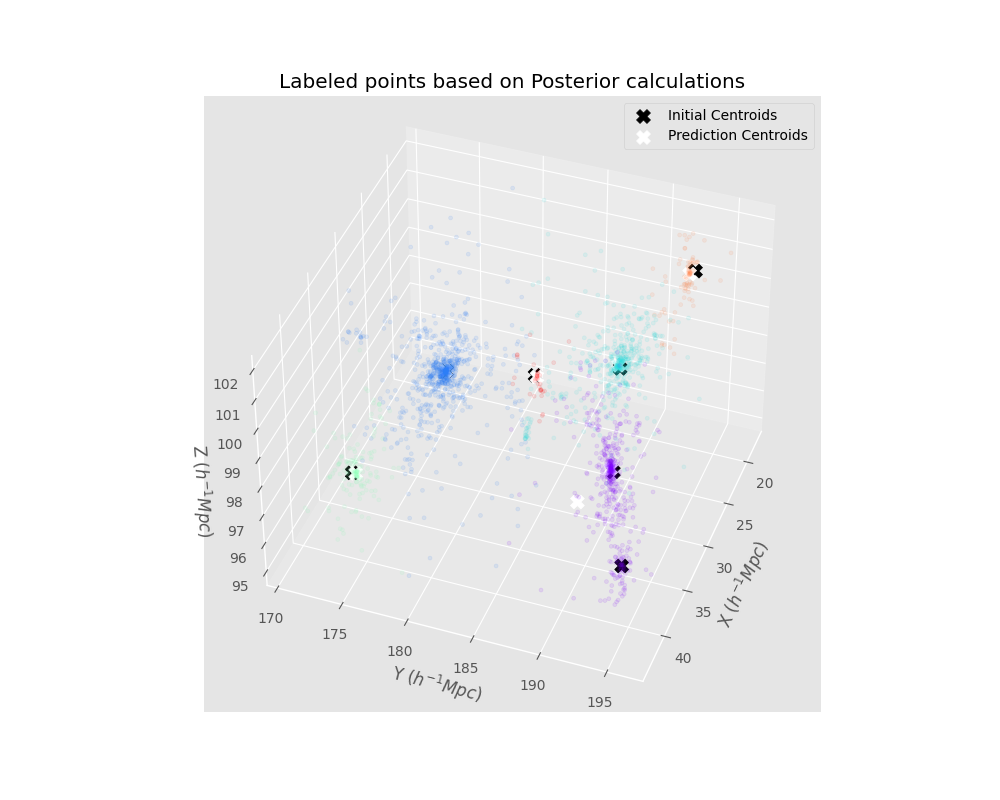

In [9]:
# Suppose 'final_params' is the best-fit mixture solution
final_param = best_res.x
labels = predict_clusters(data, final_param, K, box)
print(np.asarray(np.unique(labels, return_counts=True)).T)

pred_cent = np.array(pred_cent)

# Visualization of initial guess (using matplotlib for plotting)
cent = center_result
plt.style.use('ggplot')
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(data[:,0], data[:,1], data[:,2], s=8, c=labels, cmap='rainbow', marker='o', alpha=0.1)
ax.scatter(cent[:, 0], cent[:, 1], cent[:, 2],
           s=100, c='black', marker='X', label='Initial Centroids', alpha=1)

ax.scatter(pred_cent[:, 0], pred_cent[:, 1], pred_cent[:, 2],
           s=100, c='white', marker='X', label='Prediction Centroids', alpha=1)
ax.set_xlabel('X ($h^{-1}Mpc$)')
ax.set_ylabel('Y ($h^{-1}Mpc$)')
ax.set_zlabel('Z ($h^{-1}Mpc$)')
ax.set_title('Labeled points based on Posterior calculations')
ax.view_init(elev=40., azim=20)
plt.legend()
plt.show()

## P3.5 Performance Analysis

#### 1. Residual Analysis:

The 3D quad (grid) cells, count how many data points fall in each, and
compute the predicted counts from the final model.

* Raw residual$=O-P.$

* Pearson residual$=\frac{O-P}{\sqrt{P}}$(if $P>0).$

The below plot of a few z-slices is available to see if there are large systematic under/over estimations.

#### 2. `AIC`/`BIC`:

* From the final negative log-likelihood (NLL) and the param count (p) the values for Akaike Information Criterion `AIC`=$2k-2ln(L)$.
  Where $k$ is the number of model's parameters and $L$ is the maximized value of likelihood function of the model.

* Similarly Bayesian Information Criterion `BIC`=$-2ln(L)+kln(L)$ penalizes model complexity more heavily than some other criteria (like AIC), especially when you have a large dataset.

#### 3. Visualizing or Inspecting:

* This code prints each cluste$r^{\prime }$s final center, scale radius, and Einasto index. $\bullet$ Larqe positive residual slices ( in red) = underfittinq ( model< data) . Larqe neqative s| ices
(blue)=overfitting (model> data). A roughhy neutral pattern means the model is capturing
the distribution well.


AIC=8783.41
BIC=9025.95


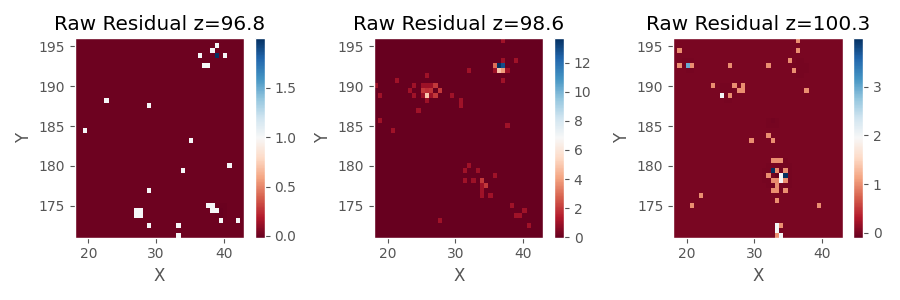

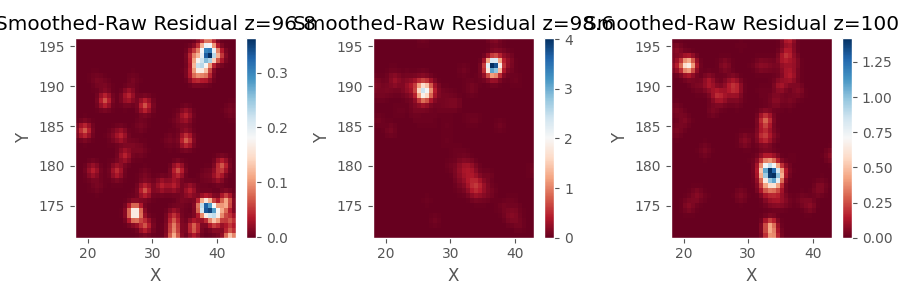

In [12]:
##############################################################################
#  RESIDUAL ANALYSIS
##############################################################################

# compute AIC/BIC
p = len(final_param)  # param count
nll = best_res.fun
AIC, BIC = compute_AIC_BIC(nll, N, p)
print(f"AIC={AIC:.2f}")
print(f"BIC={BIC:.2f}")

# Residual visualization
raw_resid, pearson_resid, xmid, ymid, zmid = compute_3d_residuals(data, box, final_param, K=K)
# Slices for raw residuals
plot_residual_slices(raw_resid, xmid, ymid, zmid, slice_idxs=[10,20,30], title="Raw Residual")

# Slices for smoothed raw residuals
smoothed_resid = gaussian_filter(raw_resid, sigma=1)
plot_residual_slices(smoothed_resid, xmid, ymid, zmid, slice_idxs=[10,20,30], title="Smoothed-Raw Residual")

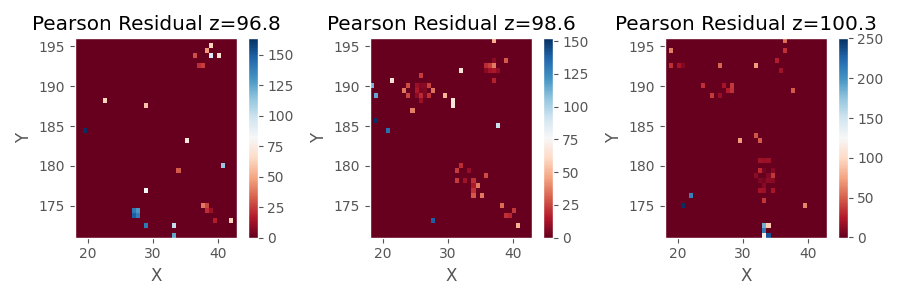

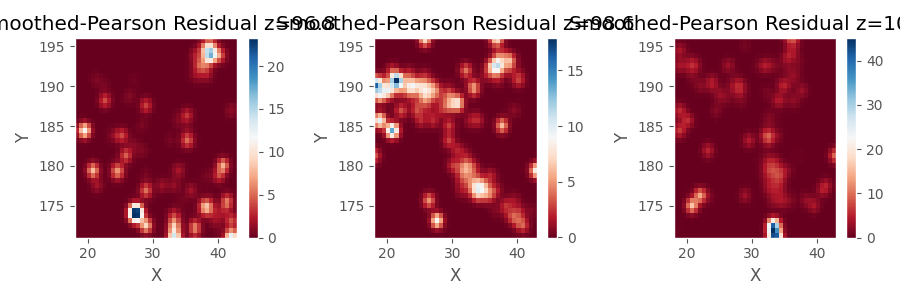

In [13]:
# Slices for pearson residuals
plot_residual_slices(pearson_resid, xmid, ymid, zmid, slice_idxs=[10,20,30], title="Pearson Residual")

# Slices for smoothed pearson residuals
smoothed_pear_resid = gaussian_filter(pearson_resid, sigma=1)
plot_residual_slices(smoothed_pear_resid, xmid, ymid, zmid, slice_idxs=[10,20,30], title="Smoothed-Pearson Residual")

<a name='section_4'></a>
<hr style="height: 1px;">
<h2 style="border:1px; border-style:solid; padding: 0.25em; color: #FFFFFF; background-color: #30609C">P4. Conclusion</h2>



### P4.1 Discussion

* **Mixture Model Fit with Constraints:** In this project, I have employed an unsupervised, finite mixture model combining halo components (Einasto profile) to detect halo clusters with uniformly distributed background component.
* **Parameter Recovery:** The model is fit with 3-d data from Bolshoi cosmological simulation and Through maximum-likelihood estimation (and model selection via criteria such as AIC/BIC), the framework recovers key halo parameters such as center coordinates, scale radii, and shape indices.
* **Consistency with Cosmological Models:** The model estimates parameters that are consistent with expectations of cosmological theoretical models.
* **Initial Candidate Identification:** An initial estimation step using kernel density estimation enhances convergence and accuracy of MLE optimization algorithm.
___
### P4.2 Future Directions

* <h5>Refinement of Halo Models</h5>

    * <u>Incorporate More Realistic Profiless</u> : While this project uses an Einasto profile as a physically motivated model, future work could explore more complex or flexible profiles. For example, allowing for triaxial (non-spherical) halos, or incorporating substructure within halos.

    * <u>Hybrid Approaches</u>: Combine the parametric constraints of the Einasto profile with non-parametric techniques to tackle with "deviations" or "asymmetries" in halo shapes

* <h5> Advanced Parameter Estimation and Inference</h5>

    * Enhanced Optimization Techniques by incorporating advanced algorithms such as variational inference, Markov Chain Monte Carlo methods (MCMC), or advanced Expectation-Maximization variants improves convergence and avoid trapping in local optima.

    * Uncertainty Quantification by integrating a fully Bayesian framework.

* <h5>Scalability and Computational Efficiency</h5>

    * Handling Large Datasets with the proposed optimizations is computationally expensive. Boosting computational resources with parallel computing results processing larger dataset.

    * Real-time or On-demand Analysis: Developing faster versions of the algorithm could enable real-time detection and characterization in survey
pipelines.

* <h5>Integration with Multi-Wavelength and Multi-Probe Data</h5>

    * Dark matter halos are observed indirectly via gravitational lensing, and X-ray emissions. Future work might involve integrating these multi-wavelength datasets within the mixture modeling framework to provide tighter constraints on halo properties


* <h5>Robustness to Background Noise and Anomaly Detection</h5>

    * <u>Improved Background Modeling</u>: Currently, the backqround is often modeled as uniform. A more realistic treatment miqht
involve structured or correlated backgrounds, which are common in real obsenvations.

    * <u>Model Selection and Validation</u>: Future studies could focus on developing robust criteria (such as cross-validation methods) to determine the optimal number of halo components and to assess the model's performance in the presence of obsenvational noise

___
### P4.3 References

[1] Kuhn, M. A., & Feigelson, E. D. (2017). Mixture models in astronomy. arXiv preprint arXiv:1711.11101.

[2] Hurtado-Gil, L., Kuhn, M. A., Arnalte-Mur, P., Feigelson, E. D., & Martínez, V. (2022). DarkMix: Mixture Models for the Detection and Characterization of Dark Matter Halos. The Astrophysical Journal, 939(1), 34.

[3] Everitt, B. S., Landau, S., & Leese, M. (2011). Stahl D.: Cluster Analysis. Wiley, London.

